# Demo 3b: More Physics Tests for the World Model

Five new scenes. Each one has a **physically correct** version and one or two **impossible** versions. Within a scene, every version has an identical "past" (first half). Only the "future" differs.

| Scene | Physical | Impossible | Concept tested |
|---|---|---|---|
| Pendulum | swings back and forth | freezes mid-air · swings higher and higher | continuity, energy conservation |
| Collision | two balls bounce apart | pass through each other | solidity |
| Hidden ball | rolls behind a screen and out | never comes out · comes out a different colour | object permanence, identity |
| Table edge | rolls off and falls | floats off the edge (cartoon physics) | gravity |
| Ramp | speeds up down the slope | slows and rolls back uphill | gravity, energy |

The scenes are defined in `physics_videos.py`. The last section also runs **every `.mp4` in the `videos/` folder**, so you can drop in your own phone recordings.

In [1]:
import os, glob, time
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoVideoProcessor, AutoModel, AutoModelForVideoClassification
import physics_videos as pv

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
WORLD_MODEL_ID = "facebook/vjepa2-vitl-fpc64-256"
CLASSIFIER_ID = "facebook/vjepa2-vitl-fpc16-256-ssv2"

processor = AutoVideoProcessor.from_pretrained(WORLD_MODEL_ID)
wm = AutoModel.from_pretrained(WORLD_MODEL_ID).to(device).eval()
clf_processor = AutoVideoProcessor.from_pretrained(CLASSIFIER_ID)
clf = AutoModelForVideoClassification.from_pretrained(CLASSIFIER_ID).to(device).eval()

cfg = wm.config
TUBELET = getattr(cfg, "tubelet_size", 2)
GRID = getattr(cfg, "crop_size", 256) // getattr(cfg, "patch_size", 16)
TPF = GRID * GRID
print("device:", device)

/Users/astrobalaji/Documents/SIET/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 652/652 [00:00<00:00, 6782.41it/s]


device: mps


In [2]:
def run_encoder(pix):
    try:
        return wm.encoder(pixel_values_videos=pix).last_hidden_state
    except TypeError:
        return wm(pixel_values_videos=pix, skip_predictor=True).last_hidden_state

def run_predictor(pix, ctx, n_ctx, n_all):
    cmask = [torch.arange(n_ctx, device=device).unsqueeze(0)]
    tmask = [torch.arange(n_ctx, n_all, device=device).unsqueeze(0)]
    enc_in = torch.cat([ctx, ctx.new_zeros(1, n_all - n_ctx, ctx.shape[-1])], 1)
    try:
        return wm.predictor(encoder_hidden_states=enc_in, context_mask=cmask, target_mask=tmask).last_hidden_state
    except TypeError:
        return wm(pixel_values_videos=pix, context_mask=cmask, target_mask=tmask).predictor_output.last_hidden_state

@torch.no_grad()
def surprise(video):
    # video: (T, H, W, 3) uint8, any length -> mean surprise over the future half
    v = torch.from_numpy(pv.to16(video)).permute(0, 3, 1, 2)
    pix = processor(v, return_tensors="pt")["pixel_values_videos"].to(device)
    T = pix.shape[1]; Tc = T // 2
    n_ctx, n_all = (Tc // TUBELET) * TPF, (T // TUBELET) * TPF
    target = run_encoder(pix)[:, n_ctx:]
    pred = run_predictor(pix, run_encoder(pix[:, :Tc]), n_ctx, n_all)
    D = pred.shape[-1]
    err = (F.layer_norm(pred.float(), (D,)) - F.layer_norm(target.float(), (D,))).abs().mean(-1)[0]
    return err.view(-1, TPF).mean(-1).cpu().numpy()          # one value per future time-step

@torch.no_grad()
def classify(video, k=3):
    v = torch.from_numpy(pv.to16(video)).permute(0, 3, 1, 2)
    probs = clf(**clf_processor(v, return_tensors="pt").to(device)).logits.softmax(-1)[0].float().cpu()
    top = probs.topk(k)
    return [(clf.config.id2label[int(i)], float(p)) for p, i in zip(top.values, top.indices)]

## The five scenes

The grey border marks the past (what the encoder sees). The amber border marks the future (what it must predict).

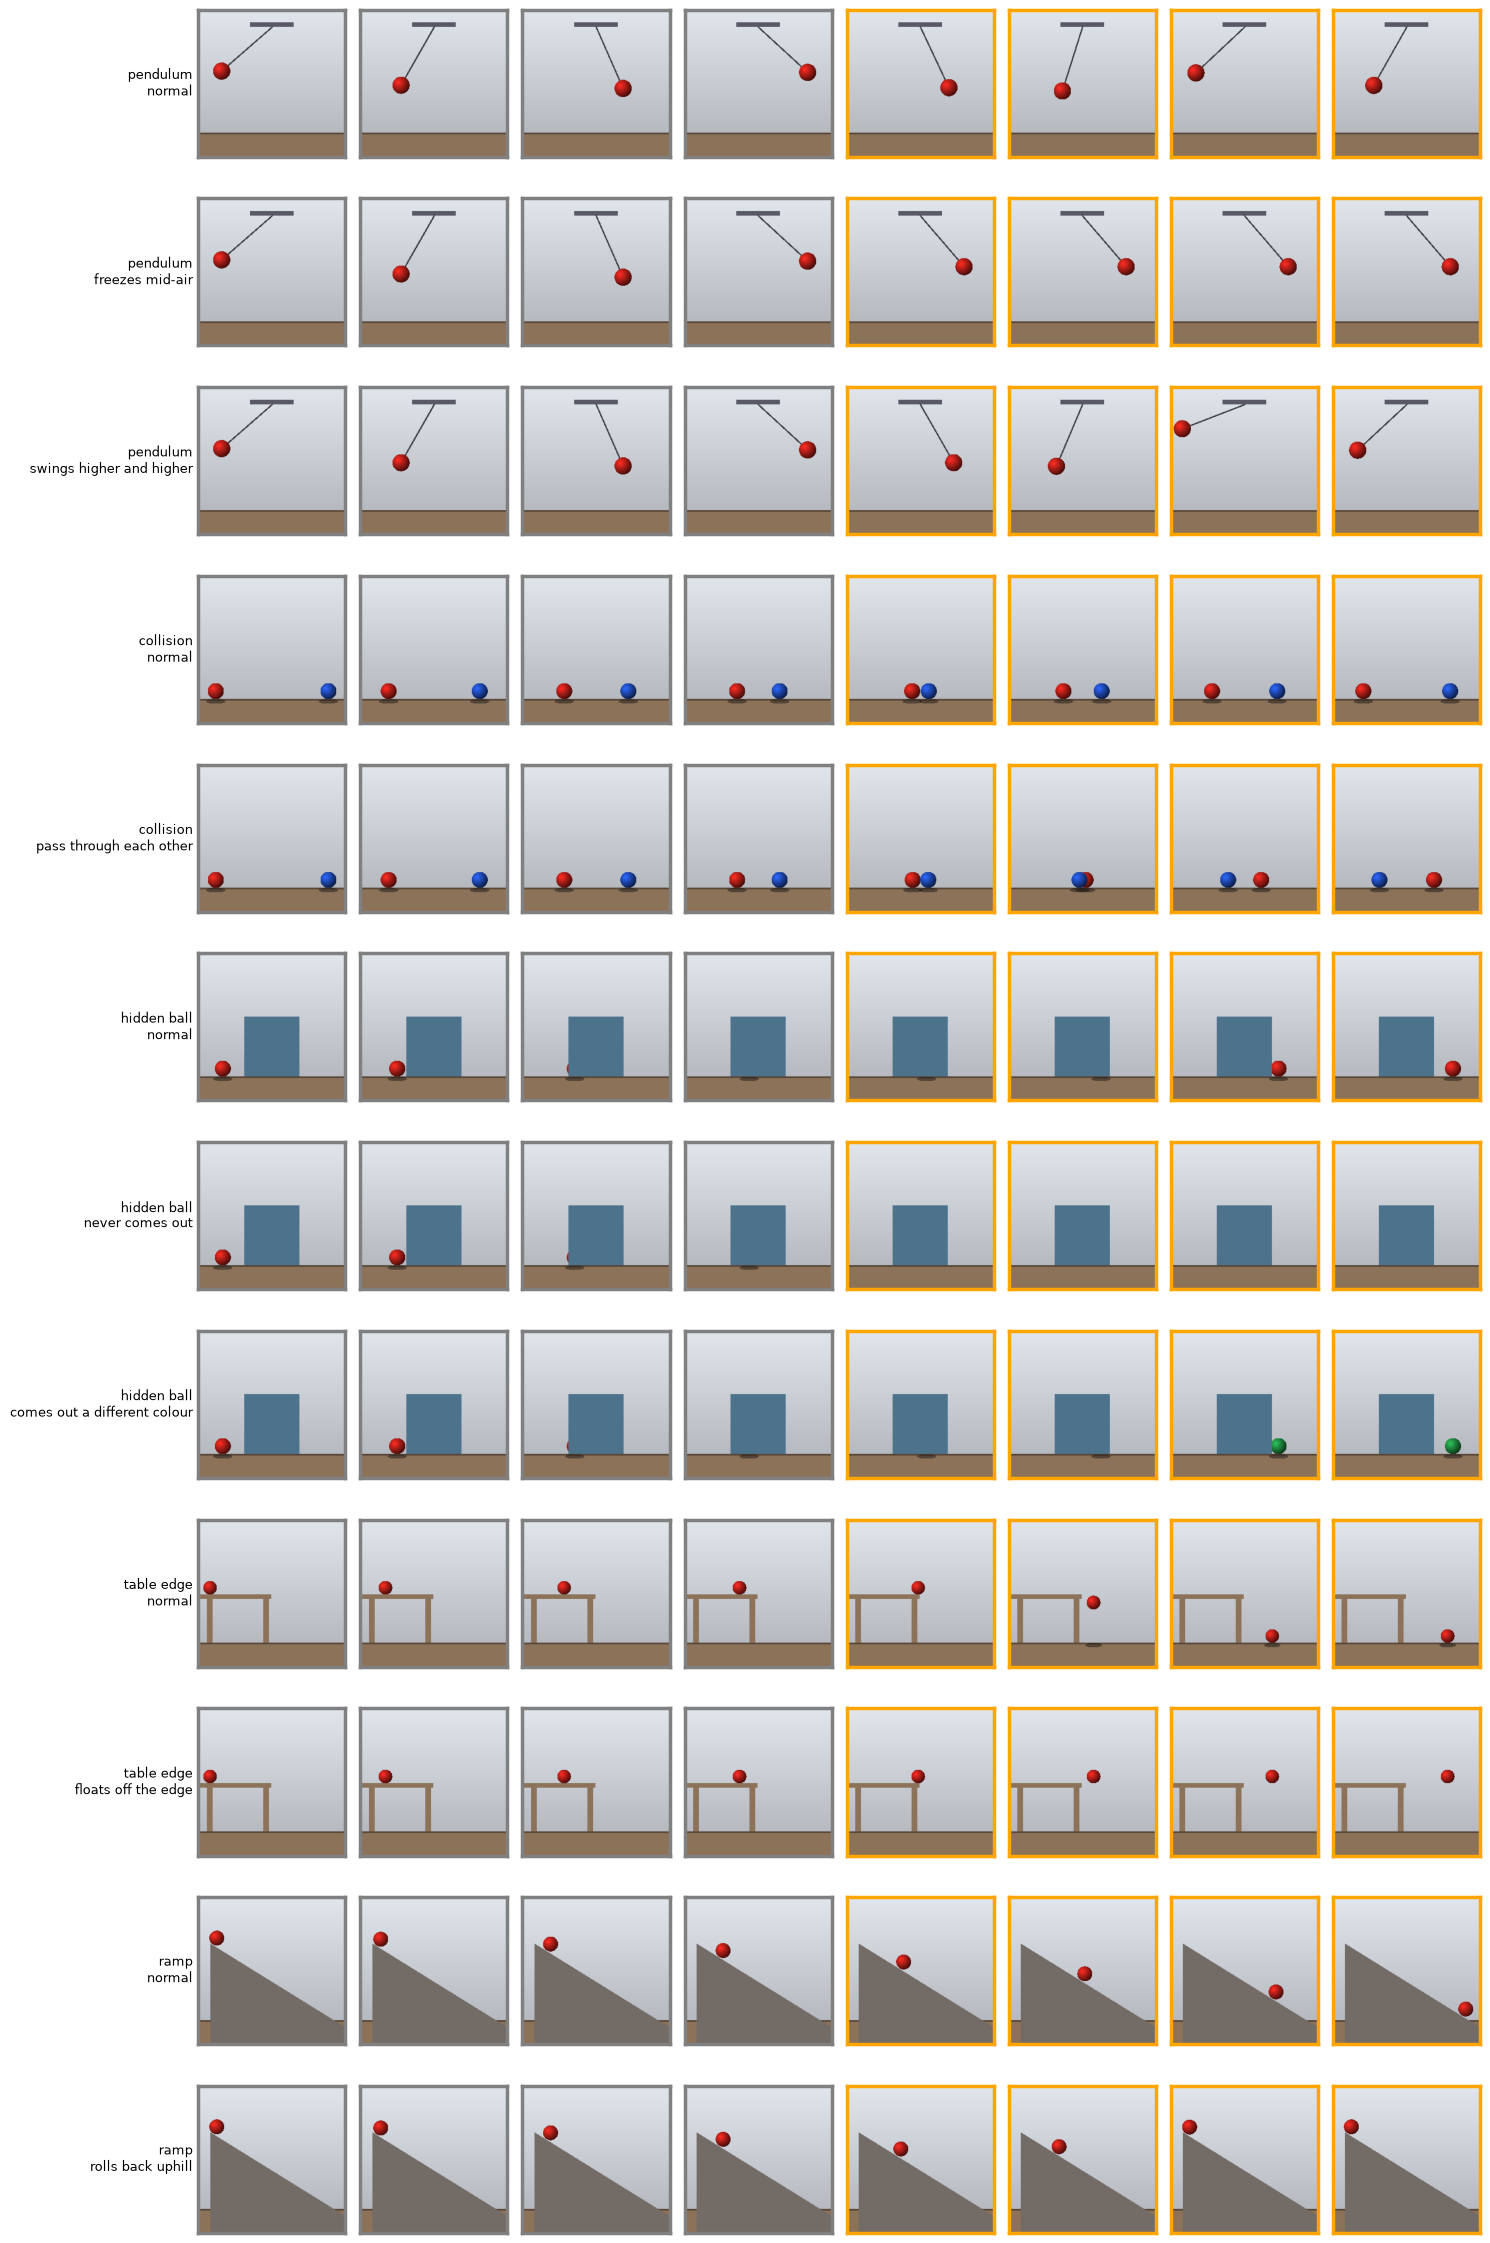

In [3]:
scenes = pv.all_scenes(seed=0)
rows = [(s, v, vid) for s, d in scenes.items() for v, vid in d.items()]
fig, axes = plt.subplots(len(rows), 8, figsize=(15, 1.9 * len(rows)))
for r, (s, v, vid) in enumerate(rows):
    for c, t in enumerate(np.linspace(0, len(vid) - 1, 8).round().astype(int)):
        ax = axes[r, c]; ax.imshow(vid[t]); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values(): sp.set_color("orange" if t > pv.HALF else "grey"); sp.set_linewidth(2.5)
    axes[r, 0].set_ylabel(f"{s}\n{v}", rotation=0, ha="right", va="center", fontsize=9)
plt.tight_layout(); plt.show()

## Surprise test

For each scene we average over several random versions (slightly different speeds and starting points) and compare each impossible version with the physical one. **Above 1.0 means the impossible video surprised the model more.**

36 videos in 45 s

scene          version                          surprise vs normal
pendulum       normal                             1.00x ± 0.00
pendulum       freezes mid-air                    0.99x ± 0.00  ✘ not surprised
pendulum       swings higher and higher           0.99x ± 0.00  ✘ not surprised

collision      normal                             1.00x ± 0.00
collision      pass through each other            0.98x ± 0.00  ✘ not surprised

hidden ball    normal                             1.00x ± 0.00
hidden ball    never comes out                    0.98x ± 0.00  ✘ not surprised
hidden ball    comes out a different colour       1.00x ± 0.00  ✘ not surprised

table edge     normal                             1.00x ± 0.00
table edge     floats off the edge                0.96x ± 0.00  ✘ not surprised

ramp           normal                             1.00x ± 0.00
ramp           rolls back uphill                  1.00x ± 0.00  ✘ not surprised



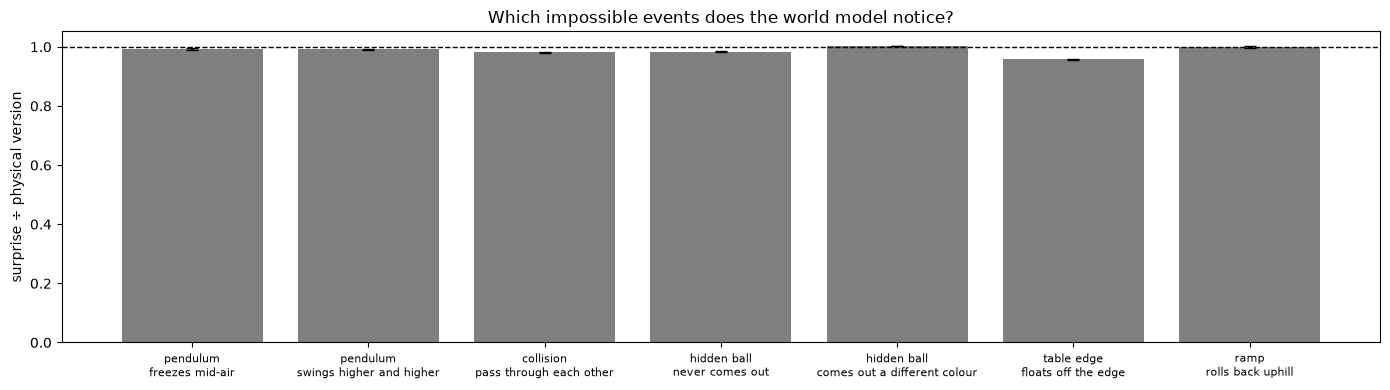

In [4]:
N_SEEDS = 3
res = {}                       # (scene, variant) -> list of mean surprise
t0 = time.time()
for seed in range(N_SEEDS):
    for s, d in pv.all_scenes(seed).items():
        for v, vid in d.items():
            res.setdefault((s, v), []).append(surprise(vid).mean())
print(f"{len(res) * N_SEEDS} videos in {time.time() - t0:.0f} s\n")

print(f"{'scene':14s} {'version':30s} {'surprise vs normal':>20s}")
bars = []
for s in scenes:
    base = np.array(res[(s, "normal")])
    for v in scenes[s]:
        ratio = np.array(res[(s, v)]) / base
        flag = "" if v == "normal" else ("  ✔ more surprised" if ratio.mean() > 1.02 else "  ✘ not surprised")
        print(f"{s:14s} {v:30s} {ratio.mean():8.2f}x ± {ratio.std():.2f}{flag}")
        if v != "normal": bars.append((f"{s}\n{v}", ratio.mean(), ratio.std()))
    print()

fig, ax = plt.subplots(figsize=(14, 4))
cols = ["tab:red" if m > 1.02 else "tab:gray" for _, m, _ in bars]
ax.bar(range(len(bars)), [m for _, m, _ in bars], yerr=[e for _, _, e in bars], color=cols, capsize=4)
ax.axhline(1, color="k", ls="--", lw=1); ax.set_xticks(range(len(bars)))
ax.set_xticklabels([n for n, _, _ in bars], fontsize=8); ax.set_ylabel("surprise ÷ physical version")
ax.set_title("Which impossible events does the world model notice?"); plt.tight_layout(); plt.show()

## What does the action classifier think is happening?

In [5]:
for s, d in scenes.items():
    for v in list(d)[:2]:
        preds = classify(d[v])
        print(f"{s:12s} | {v:28s} | " + "   ".join(f"{p * 100:4.0f}% {l}" for l, p in preds))

pendulum     | normal                       |   28% Spinning [something] so it continues spinning     19% Holding [something] in front of [something]      7% Moving [something] and [something] closer to each other
pendulum     | freezes mid-air              |   30% Pushing [something] from left to right     12% Moving [something] closer to [something]      9% Spinning [something] so it continues spinning
collision    | normal                       |   64% [Something] colliding with [something] and both are being deflected     13% Moving [something] and [something] so they collide with each other      8% [Something] being deflected from [something]
collision    | pass through each other      |   90% Moving [something] and [something] so they pass each other      5% [Something] colliding with [something] and both are being deflected      1% [Something] being deflected from [something]
hidden ball  | normal                       |   64% Turning the camera left while filming [something]   

## Your own videos

Put any number of phone clips (`.mp4` or `.mov`) in a folder called `videos/` next to this notebook and re-run. Each clip is centre-cropped to a square and 16 frames are sampled evenly.

For a real surprise comparison, record **pairs** with the same start: e.g. `drop_normal.mp4` and `drop_trick.mp4`, where in the trick version you secretly catch the ball, or swap the object behind a book.

In [6]:
import cv2

def load_video(path, n_frames=32, size=256):
    cap = cv2.VideoCapture(path); frames = []
    while True:
        ok, fr = cap.read()
        if not ok: break
        frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
    cap.release()
    idx = np.linspace(0, len(frames) - 1, n_frames).round().astype(int)
    out = []
    for i in idx:
        f = frames[i]; h, w = f.shape[:2]; m = min(h, w)
        f = f[(h - m) // 2:(h + m) // 2, (w - m) // 2:(w + m) // 2]
        out.append(cv2.resize(f, (size, size), interpolation=cv2.INTER_AREA))
    return np.stack(out)

files = sorted(p for p in glob.glob("videos/*") if p.lower().endswith((".mp4", ".mov", ".m4v", ".avi")))
if not files:
    print("No videos found. Create a 'videos' folder next to this notebook and put clips in it.")
for path in files:
    vid = load_video(path)
    fig, axes = plt.subplots(1, 8, figsize=(15, 2))
    for a, t in zip(axes, np.linspace(0, len(vid) - 1, 8).round().astype(int)): a.imshow(vid[t]); a.axis("off")
    axes[0].set_title(os.path.basename(path), loc="left"); plt.show()
    print("   surprise (future half):", round(float(surprise(vid).mean()), 3))
    for l, p in classify(vid):
        print(f"   {p * 100:5.1f}%  {l}")

No videos found. Create a 'videos' folder next to this notebook and put clips in it.


## Save the synthetic scenes as video files

Writes every scene to `videos/generated/` so you can play them full-screen (QuickTime) while explaining. They're kept out of the `videos/` loop above.

In [7]:
for p in pv.save_all("videos/generated"):
    print("wrote", p)

wrote videos/generated/pendulum__normal.mp4
wrote videos/generated/pendulum__freezes_mid-air.mp4
wrote videos/generated/pendulum__swings_higher_and_higher.mp4
wrote videos/generated/collision__normal.mp4
wrote videos/generated/collision__pass_through_each_other.mp4
wrote videos/generated/hidden_ball__normal.mp4
wrote videos/generated/hidden_ball__never_comes_out.mp4
wrote videos/generated/hidden_ball__comes_out_a_different_colour.mp4
wrote videos/generated/table_edge__normal.mp4
wrote videos/generated/table_edge__floats_off_the_edge.mp4
wrote videos/generated/ramp__normal.mp4
wrote videos/generated/ramp__rolls_back_uphill.mp4
